Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

In [2]:
from surprise import Dataset, Reader, SVD
from surprise.model_selection import train_test_split
from surprise import accuracy

In [3]:
from sklearn.decomposition import TruncatedSVD
from scipy.sparse import csr_matrix
from sklearn.metrics import mean_squared_error
from math import sqrt

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

Loading Dataset

In [5]:
file_path = r"D:\projects\amazon_product_reviews_recommender_system\Office_Products_5.json\Office_Products_5.json"

# Loading as a list of dicts first
data = []
with open(file_path, 'r') as f:
    for line in f:
        data.append(json.loads(line))

# Converting to pandas DataFrame
df = pd.DataFrame(data)

print(df.shape)
print(df.columns)
df.head()

(800357, 12)
Index(['overall', 'verified', 'reviewTime', 'reviewerID', 'asin', 'style',
       'reviewerName', 'reviewText', 'summary', 'unixReviewTime', 'vote',
       'image'],
      dtype='object')


,overall,verified,reviewTime,reviewerID,asin,style,reviewerName,reviewText,summary,unixReviewTime,vote,image
0,4.0,True,"11 7, 2017",A2NIJTYWADLK57,0140503528,{'Format:': ' Board book'},cotton clay,kids like story BUT while i really wanted a bo...,"good story, small size book though",1510012800,NaN,NaN
1,4.0,True,"03 7, 2017",A2827D8EEURMP4,0140503528,{'Format:': ' Hardcover'},emankcin,Bought this used and it came in great conditio...,Good,1488844800,NaN,NaN
2,5.0,True,"06 25, 2016",APB6087F4J09J,0140503528,{'Format:': ' Board book'},Starbucks Fan,Every story and book about Corduroy is Fantast...,Best Books for All Children,1466812800,NaN,NaN
3,5.0,True,"02 21, 2016",A2DHERRZIPFU7X,0140503528,{'Format:': ' Paperback'},Caitlyn Jacobson,I purchased this book for my first grade class...,Great for Math!,1456012800,NaN,NaN
4,5.0,False,"08 2, 2015",A2XCLJRGFANRC,0140503528,{'Format:': ' Hardcover'},E. Ervin,Having spent numerous years in an elementary s...,Love Corduroy,1438473600,NaN,NaN


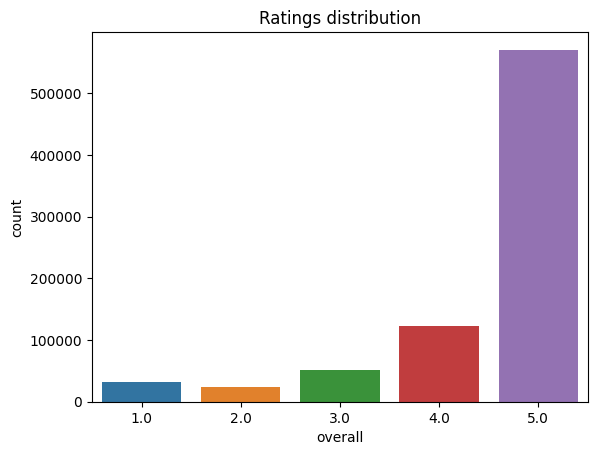

Number of unique users: 101501
Number of unique items: 27965
Avg ratings per user: 7.89
Avg ratings per item: 28.62
Dataset sparsity: 99.9718%


In [4]:
# Ratings distribution
sns.countplot(x='overall', data=df)
plt.title("Ratings distribution")
plt.show()

# Unique users and items
num_users = df['reviewerID'].nunique()
num_items = df['asin'].nunique()
print(f"Number of unique users: {num_users}")
print(f"Number of unique items: {num_items}")

# Average number of ratings per user
ratings_per_user = df.groupby('reviewerID').size()
print(f"Avg ratings per user: {ratings_per_user.mean():.2f}")

# Average number of ratings per item
ratings_per_item = df.groupby('asin').size()
print(f"Avg ratings per item: {ratings_per_item.mean():.2f}")

# Sparsity calculation
total_possible = num_users * num_items
sparsity = 1 - (len(df) / total_possible)
print(f"Dataset sparsity: {sparsity*100:.4f}%")

K-core filtering
- We’ll remove users/items with fewer than k ratings

In [6]:
def filter_k_core(df, user_col='reviewerID', item_col='asin', k=0):
    while True:
        before_shape = df.shape[0]
        user_counts = df[user_col].value_counts()
        item_counts = df[item_col].value_counts()

        df = df[df[user_col].isin(user_counts[user_counts >= k].index)]
        df = df[df[item_col].isin(item_counts[item_counts >= k].index)]

        after_shape = df.shape[0]

        if before_shape == after_shape:
            break
    return df

# Applying k-core
df_core_5 = filter_k_core(df.copy(), k=5)
print(f"Filtered shape: {df_core_5.shape}")
print(f"Users: {df_core_5['reviewerID'].nunique()}, Items: {df_core_5['asin'].nunique()}")

Filtered shape: (797563, 12)
Users: 101133, Items: 27500


In [11]:
df_core_10 = filter_k_core(df.copy(), k=10)
print(f"Filtered shape: {df_core_10.shape}")
print(f"Users: {df_core['reviewerID'].nunique()}, Items: {df_core_10['asin'].nunique()}")

Filtered shape: (107070, 12)
Users: 101133, Items: 3755


In [7]:
df_core = filter_k_core(df.copy(), k=7)
print(f"Filtered shape: {df_core.shape}")
print(f"Users: {df_core['reviewerID'].nunique()}, Items: {df_core['asin'].nunique()}")

Filtered shape: (369953, 12)
Users: 33828, Items: 12296


Simple popularity-based recommender system
- baseline before collaborative filtering or deep models
- fallback recommendation for new users with no interaction history (cold start)
- Same recommendations to all users

In [14]:
# Calculating item popularity (number of ratings)
item_popularity = df_core.groupby('asin').size().sort_values(ascending=False)

# Top-N popular items
top_N = 10
top_items = item_popularity.head(top_N).index.tolist()

print(f"Top {top_N} popular items: {top_items}")

# Function to recommend top-N items to any user
def recommend_popular(user_id, top_items):
    return top_items

sample_user = df_core['reviewerID'].iloc[0]
print(f"Recommended for user {sample_user}: {recommend_popular(sample_user, top_items)}")

Top 10 popular items: ['B00A89YZ6S', 'B00006IFEU', 'B0010JEJPC', 'B00006IEEV', 'B00006IFI5', 'B00006JNJD', 'B000ZHB2HS', 'B0015ASS3U', 'B00006IE7J', 'B00005249G']
Recommended for user AN2FZ6SBNYDDQ: ['B00A89YZ6S', 'B00006IFEU', 'B0010JEJPC', 'B00006IEEV', 'B00006IFI5', 'B00006JNJD', 'B000ZHB2HS', 'B0015ASS3U', 'B00006IE7J', 'B00005249G']


Collaborative Filtering with SVD

In [36]:
# Define reader
reader = Reader(rating_scale=(1, 5))

# Load dataset from DataFrame
data = Dataset.load_from_df(df_core[['reviewerID', 'asin', 'overall']], reader)

# Train-test split
trainset, testset = train_test_split(data, test_size=0.2, random_state=42)

In [37]:
svd_model = SVD()
svd_model.fit(trainset)

In [42]:
predictions = svd_model.test(testset)

# Calculating RMSE
rmse = accuracy.rmse(predictions)
print(f"SVD Model RMSE: {rmse:.4f}")

RMSE: 0.8444
SVD Model RMSE: 0.8444


Collaborative Filtering via Scikit-Learn TruncatedSVD

In [22]:
# Creating user-item rating matrix
user_item_matrix = df_core.pivot_table(index='reviewerID', columns='asin', values='overall').fillna(0)

print(f"Shape: {user_item_matrix.shape}")

Shape: (33828, 12296)


In [23]:
sparse_matrix = csr_matrix(user_item_matrix.values)
svd = TruncatedSVD(n_components=20, random_state=42)
svd.fit(sparse_matrix)

TruncatedSVD(n_components=20, random_state=42)

In [24]:
# User features matrix
U = svd.transform(sparse_matrix) 

# Item features matrix
V = svd.components_.T  

print(f"U shape: {U.shape}, V shape: {V.shape}")

U shape: (33828, 20), V shape: (12296, 20)


In [25]:
# Approximate user-item ratings
approx_ratings = np.dot(U, V.T)
approx_df = pd.DataFrame(approx_ratings, index=user_item_matrix.index, columns=user_item_matrix.columns)
print(approx_df.head())

asin                  0310432065  0310520347  0310802636  0310806607  \
reviewerID                                                             
A0203183BAH3TR08FZGB    0.000174    0.000392    0.000271    0.000567   
A0228801ER3IBSLNOT5W   -0.000086    0.000210    0.001483   -0.000090   
A05012776MTIS8L40R3I    0.000138    0.000187    0.000297    0.000366   
A0759107CA9MPWVRF6VN    0.000274    0.000131    0.000083    0.000035   
A1002RB0A8LGMI          0.000167    0.000345    0.000396    0.000511   

asin                  0310821800  0439499887  0439893577  0486256006  \
reviewerID                                                             
A0203183BAH3TR08FZGB    0.000743    0.000867    0.000427    0.000621   
A0228801ER3IBSLNOT5W   -0.000513    0.001361    0.000259   -0.000223   
A05012776MTIS8L40R3I    0.000535    0.000864    0.000397    0.000481   
A0759107CA9MPWVRF6VN    0.000923   -0.000102   -0.000731   -0.000827   
A1002RB0A8LGMI          0.000856    0.001380    0.000389    0.0

In [26]:
def recommend_items(user_id, user_item_df, approx_df, N=10):
    # Actual rated items
    user_rated_items = user_item_df.loc[user_id][user_item_df.loc[user_id] > 0].index.tolist()
    
    # Predicted ratings
    user_pred_ratings = approx_df.loc[user_id]
    
    # Removing already rated items
    recommendations = user_pred_ratings.drop(labels=user_rated_items)
    
    # Sorting descending and returning top N
    top_N = recommendations.sort_values(ascending=False).head(N)
    
    return top_N

sample_user = user_item_matrix.index[0]
print(f"Top recommendations for {sample_user}:")
print(recommend_items(sample_user, user_item_matrix, approx_df, N=10))

Top recommendations for A0203183BAH3TR08FZGB:
asin
B00006JNJD    0.143642
B00002NDRX    0.102161
B00002NDRT    0.102161
B00004Z4BK    0.087088
B001CJRM36    0.086929
B00006JNNS    0.086753
B001CD7M1O    0.067517
B00006IF67    0.067195
B003YFHCKY    0.064701
B00006IE7J    0.061598
Name: A0203183BAH3TR08FZGB, dtype: float64


In [28]:
# Getting common non-zero indices
original_nonzero = user_item_matrix.values.flatten() > 0
true_ratings = user_item_matrix.values.flatten()[original_nonzero]
pred_ratings = approx_df.values.flatten()[original_nonzero]

# Calculating RMSE
trunc_svd_rmse = sqrt(mean_squared_error(true_ratings, pred_ratings))
print(f"Truncated SVD RMSE: {trunc_svd_rmse:.4f}")

Truncated SVD RMSE: 4.4104


Precision@k and Recall@k

In [29]:
from collections import defaultdict

def precision_recall_at_k(predictions, k=10, threshold=3.5):
    '''Return precision and recall at k metrics for each user.'''
    # Map the predictions to each user.
    user_est_true = defaultdict(list)
    for uid, iid, true_r, est, _ in predictions:
        user_est_true[uid].append( (est, true_r) )

    precisions = dict()
    recalls = dict()
    for uid, user_ratings in user_est_true.items():
        # Sort user ratings by estimated value
        user_ratings.sort(key=lambda x: x[0], reverse=True)

        # Number of relevant items
        n_rel = sum((true_r >= threshold) for (_, true_r) in user_ratings)

        # Number of recommended items in top k
        n_rec_k = sum((est >= threshold) for (est, _) in user_ratings[:k])

        # Number of relevant and recommended items in top k
        n_rel_and_rec_k = sum(((true_r >= threshold) and (est >= threshold))
                              for (est, true_r) in user_ratings[:k])

        # Precision@K: Proportion of recommended items that are relevant
        precisions[uid] = n_rel_and_rec_k / n_rec_k if n_rec_k != 0 else 0

        # Recall@K: Proportion of relevant items that are recommended
        recalls[uid] = n_rel_and_rec_k / n_rel if n_rel != 0 else 0

    return precisions, recalls

In [30]:
# Compute Precision@k and Recall@k
precisions, recalls = precision_recall_at_k(predictions, k=10, threshold=3.5)

# Average them
print(f'Average Precision@10: {sum(precisions.values())/len(precisions):.4f}')
print(f'Average Recall@10: {sum(recalls.values())/len(recalls):.4f}')

Average Precision@10: 0.8802
Average Recall@10: 0.9387


Content-Based Filtering

In [32]:
# Aggregating summaries for each product
product_texts = df_core.groupby('asin')['summary'].apply(lambda x: " ".join(str(s) for s in x)).reset_index()

# Fill missing summaries with empty string
product_texts['summary'] = product_texts['summary'].fillna("")

# TF-IDF Vectorization
tfidf = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf.fit_transform(product_texts['summary'])

print("TF-IDF matrix shape:", tfidf_matrix.shape)  # (num_items, num_features)

# Computing cosine similarity between items
cosine_sim = linear_kernel(tfidf_matrix, tfidf_matrix)

# Building reverse mapping of item indices
indices = pd.Series(product_texts.index, index=product_texts['asin'])

def get_similar_items(item_asin, top_n=10):
    idx = indices[item_asin]
    sim_scores = list(enumerate(cosine_sim[idx])) # (index, score)
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    sim_scores = sim_scores[1:top_n+1]  # excluding itself
    item_indices = [i[0] for i in sim_scores]
    return product_texts['asin'].iloc[item_indices].tolist()

sample_item = product_texts['asin'].iloc[0]
similar_items = get_similar_items(sample_item, top_n=5)

print(f"Items similar to {sample_item}: {similar_items}")

TF-IDF matrix shape: (12296, 22117)
Items similar to 0310432065: ['B00BLPTJTQ', 'B004J6I0Y4', 'B001L4V0XK', '9900493435', '9900493427']


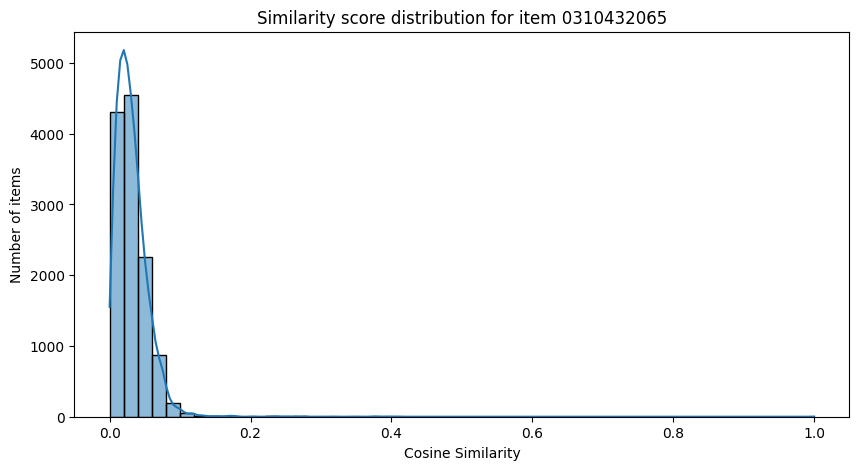

In [33]:
def plot_item_similarity(item_asin):
    idx = indices[item_asin]
    sim_scores = cosine_sim[idx]

    plt.figure(figsize=(10,5))
    sns.histplot(sim_scores, bins=50, kde=True)
    plt.title(f"Similarity score distribution for item {item_asin}")
    plt.xlabel("Cosine Similarity")
    plt.ylabel("Number of items")
    plt.show()

sample_item = product_texts['asin'].iloc[0]
plot_item_similarity(sample_item)

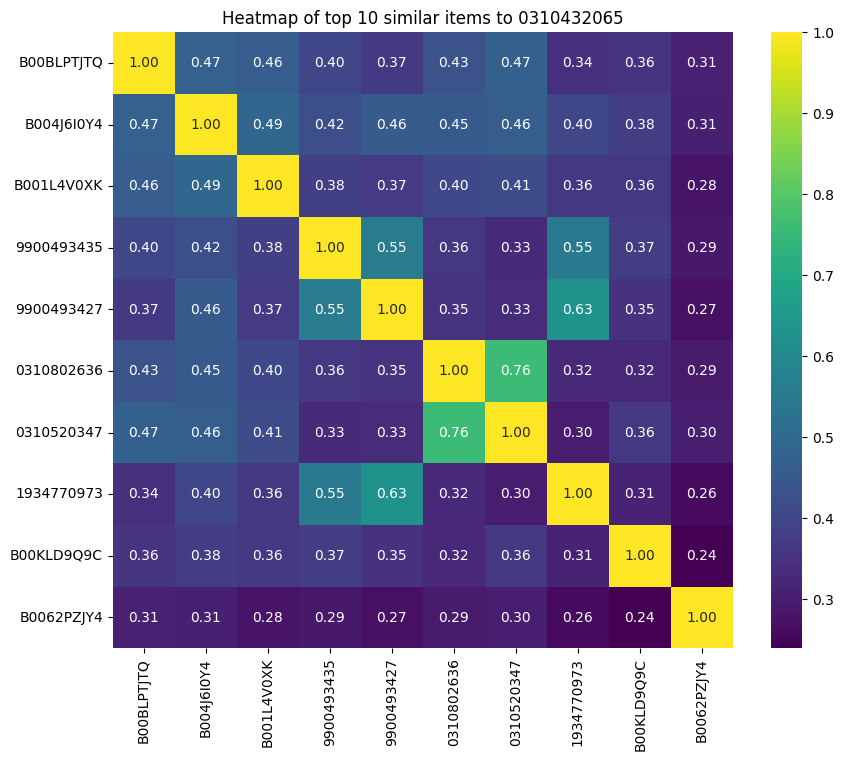

In [34]:
def plot_similarity_heatmap(item_asin, top_n=10):
    idx = indices[item_asin]
    sim_scores = list(enumerate(cosine_sim[idx]))
    sim_scores = sorted(sim_scores, key=lambda x: x[1], reverse=True)
    sim_scores = sim_scores[1:top_n+1]

    item_indices = [i[0] for i in sim_scores]
    item_names = product_texts['asin'].iloc[item_indices].tolist()

    # Extract submatrix of top-N items similarity with each other
    sim_matrix_sub = cosine_sim[np.ix_(item_indices, item_indices)]

    plt.figure(figsize=(10,8))
    sns.heatmap(sim_matrix_sub, xticklabels=item_names, yticklabels=item_names, cmap='viridis', annot=True, fmt=".2f")
    plt.title(f"Heatmap of top {top_n} similar items to {item_asin}")
    plt.show()

# Example usage
plot_similarity_heatmap(sample_item, top_n=10)

Hybrid Recommender System
- Combining Collaborative Filtering (CF) and Content-Based Filtering (CBF)

In [36]:
def get_cf_scores(user_id, candidate_items, model, df):
    scores = []
    for item_id in candidate_items:
        try:
            pred = model.predict(user_id, item_id).est
        except:
            pred = 0
        scores.append(pred)
    return scores

In [37]:
def get_cbf_scores(item_asin, candidate_items, indices, cosine_sim):
    if item_asin not in indices:
        return [0]*len(candidate_items)
    idx = indices[item_asin]
    item_scores = cosine_sim[idx]

    scores = []
    for i in candidate_items:
        if i in indices:
            scores.append(item_scores[indices[i]])
        else:
            scores.append(0)
    return scores

Approach
- Normalize CF and CBF scores to [0,1]
- Combine with a weighted sum or average
- Tune weights to balance personalization vs similarity.

In [38]:
def hybrid_recommend(user_id, item_asin, candidate_items, cf_model, df, indices, cosine_sim, cf_weight=0.5, cbf_weight=0.5, top_n=10):
    # CF scores
    cf_scores = get_cf_scores(user_id, candidate_items, cf_model, df)
    # Normalize CF scores
    cf_scores_norm = (np.array(cf_scores) - np.min(cf_scores)) / (np.max(cf_scores) - np.min(cf_scores) + 1e-8)

    # CBF scores
    cbf_scores = get_cbf_scores(item_asin, candidate_items, indices, cosine_sim)
    # Normalize CBF scores
    cbf_scores_norm = (np.array(cbf_scores) - np.min(cbf_scores)) / (np.max(cbf_scores) - np.min(cbf_scores) + 1e-8)

    # Combined scores
    combined_scores = cf_weight * cf_scores_norm + cbf_weight * cbf_scores_norm

    # Rank items
    ranked_indices = np.argsort(combined_scores)[::-1]
    recommended_items = [candidate_items[i] for i in ranked_indices[:top_n]]

    return recommended_items

In [43]:
candidate_items = df_core['asin'].unique().tolist()
sample_user = df_core['reviewerID'].iloc[0]
sample_item = df_core['asin'].iloc[0]

hybrid_recs = hybrid_recommend(sample_user, sample_item, candidate_items, svd_model, df_core, indices, cosine_sim, cf_weight=0.7, cbf_weight=0.3, top_n=10)

print("Hybrid recommended items:", hybrid_recs)

Hybrid recommended items: ['0310432065', 'B00BLPTJTQ', 'B004J6I0Y4', '9900493427', 'B00KLD9Q9C', 'B001L4V0XK', 'B006X0TF70', '0310802636', '1934770973', 'B001CRI6O2']


In [44]:
def precision_at_k(actual, predicted, k):
    pred_k = predicted[:k]
    num_hit = len(set(pred_k) & set(actual))
    return num_hit / k

def recall_at_k(actual, predicted, k):
    pred_k = predicted[:k]
    num_hit = len(set(pred_k) & set(actual))
    return num_hit / len(actual) if actual else 0

In [45]:
k = 10
precisions, recalls = [], []

sample_users = df_core['reviewerID'].unique()[:100]

for user in sample_users:
    user_items = df_core[df_core['reviewerID'] == user]['asin'].tolist()
    candidate_items = df_core['asin'].unique().tolist()

    # Generating hybrid recommendations
    recs = hybrid_recommend(user, user_items[0], candidate_items, svd_model, df_core, indices, cosine_sim, cf_weight=0.7, cbf_weight=0.3, top_n=k)

    # Evaluation
    precisions.append(precision_at_k(user_items, recs, k))
    recalls.append(recall_at_k(user_items, recs, k))
    
print(f"Hybrid Precision@{k}: {np.mean(precisions):.4f}")
print(f"Hybrid Recall@{k}: {np.mean(recalls):.4f}")

Hybrid Precision@10: 0.1030
Hybrid Recall@10: 0.0963


Neural Collaborative Filtering
- implementing a Neural Matrix Factorization model (NeuMF)

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import pandas as pd
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


Prepare Dataset

In [3]:
class NCFDataset(Dataset):
    def __init__(self, df, user2idx, item2idx, num_negatives=4):
        self.user_input = []
        self.item_input = []
        self.labels = []
        
        users, items = df['reviewerID'], df['asin']
        self.df_set = set(zip(users, items))
        
        for user, item in self.df_set:
            self.user_input.append(user2idx[user])
            self.item_input.append(item2idx[item])
            self.labels.append(1)
            
            # Negative sampling
            for _ in range(num_negatives):
                neg_item = np.random.choice(list(item2idx.keys()))
                while (user, neg_item) in self.df_set:
                    neg_item = np.random.choice(list(item2idx.keys()))
                self.user_input.append(user2idx[user])
                self.item_input.append(item2idx[neg_item])
                self.labels.append(0)
    
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        return torch.tensor(self.user_input[idx]), torch.tensor(self.item_input[idx]), torch.tensor(self.labels[idx], dtype=torch.float)

In [4]:
class NCFDataset(Dataset):
    def __init__(self, df, user2idx, item2idx, num_negatives=4):
        self.user_input = []
        self.item_input = []
        self.labels = []
        
        users, items = df['reviewerID'], df['asin']
        self.df_set = set(zip(users, items))
        
        all_items = set(item2idx.keys())
        user_pos_items = df.groupby('reviewerID')['asin'].apply(set).to_dict()
        
        for user, item in self.df_set:
            self.user_input.append(user2idx[user])
            self.item_input.append(item2idx[item])
            self.labels.append(1)
            
            neg_candidates = list(all_items - user_pos_items[user])
            sampled_negatives = np.random.choice(neg_candidates, size=num_negatives, replace=len(neg_candidates)<num_negatives)
            for neg_item in sampled_negatives:
                self.user_input.append(user2idx[user])
                self.item_input.append(item2idx[neg_item])
                self.labels.append(0)
    
    def __len__(self):
        return len(self.labels)
    
    def __getitem__(self, idx):
        return (
            torch.tensor(self.user_input[idx]),
            torch.tensor(self.item_input[idx]),
            torch.tensor(self.labels[idx], dtype=torch.float)
        )

In [20]:
from sklearn.model_selection import train_test_split
train_df, val_df = train_test_split(df_core, test_size=0.1, random_state=42)

In [21]:
# Encoding user and item ids
user2idx = {user: idx for idx, user in enumerate(df_core['reviewerID'].unique())}
item2idx = {item: idx for idx, item in enumerate(df_core['asin'].unique())}

train_dataset = NCFDataset(train_df, user2idx, item2idx, num_negatives=4)
train_loader = DataLoader(train_dataset, batch_size=1024, shuffle=True)

In [22]:
# Defining NeuMF Model
class NeuMF(nn.Module):
    def __init__(self, num_users, num_items, mf_dim=8, mlp_layers=[64,32,16,8]):
        super(NeuMF, self).__init__()
        # Embeddings
        self.user_embedding_mf = nn.Embedding(num_users, mf_dim)
        self.item_embedding_mf = nn.Embedding(num_items, mf_dim)
        
        self.user_embedding_mlp = nn.Embedding(num_users, int(mlp_layers[0]/2))
        self.item_embedding_mlp = nn.Embedding(num_items, int(mlp_layers[0]/2))
        
        # MLP layers
        mlp_modules = []
        for i in range(len(mlp_layers)-1):
            mlp_modules.append(nn.Linear(mlp_layers[i], mlp_layers[i+1]))
            mlp_modules.append(nn.ReLU())
        self.mlp = nn.Sequential(*mlp_modules)
        
        # Final prediction layer
        self.predict_layer = nn.Linear(mf_dim + mlp_layers[-1], 1)
        self.sigmoid = nn.Sigmoid()
        
    def forward(self, user, item):
        # GMF
        mf_user = self.user_embedding_mf(user)
        mf_item = self.item_embedding_mf(item)
        mf_vector = mf_user * mf_item
        
        # MLP
        mlp_user = self.user_embedding_mlp(user)
        mlp_item = self.item_embedding_mlp(item)
        mlp_vector = torch.cat([mlp_user, mlp_item], dim=-1)
        mlp_vector = self.mlp(mlp_vector)
        
        # Concatenate and final prediction
        vector = torch.cat([mf_vector, mlp_vector], dim=-1)
        logits = self.predict_layer(vector)
        output = self.sigmoid(logits)
        return output.squeeze()

In [25]:
def evaluate_model(model, val_df, user2idx, item2idx, k=10):
    model.eval()
    precision_scores, recall_scores = [], []

    user_item_matrix = val_df.groupby('reviewerID')['asin'].apply(list).to_dict()
    device = next(model.parameters()).device

    with torch.no_grad():
        for user in tqdm(user_item_matrix.keys(), desc="Evaluating"):
            if user not in user2idx:
                continue

            user_idx = torch.tensor([user2idx[user]], device=device)
            all_items = list(item2idx.keys())
            item_indices = torch.tensor([item2idx[item] for item in all_items], device=device)

            user_expand = user_idx.repeat(len(item_indices))

            outputs = model(user_expand, item_indices)
            topk_indices = torch.topk(outputs, k).indices.cpu().numpy()

            recommended_items = [all_items[i] for i in topk_indices]
            true_items = user_item_matrix[user]

            # Precision@k
            num_hits = len(set(recommended_items) & set(true_items))
            precision = num_hits / k
            recall = num_hits / len(true_items) if len(true_items) > 0 else 0

            precision_scores.append(precision)
            recall_scores.append(recall)

    avg_precision = np.mean(precision_scores)
    avg_recall = np.mean(recall_scores)

    return avg_precision, avg_recall

In [26]:
num_users = len(user2idx)
num_items = len(item2idx)

model = NeuMF(num_users, num_items).to(device)
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 3

for epoch in range(epochs):
    model.train()
    total_loss = 0
    for user, item, label in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
        user, item, label = user.to(device), item.to(device), label.to(device)
        optimizer.zero_grad()
        output = model(user, item)
        loss = criterion(output, label)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch+1}/{epochs}, Train Loss: {avg_loss:.4f}")

    # Evaluation on validation set
    precision, recall = evaluate_model(model, val_df, user2idx, item2idx, k=10)
    print(f"Validation Precision@10: {precision:.4f}, Recall@10: {recall:.4f}")

Epoch 1/3: 100%|███████████████████████████████████████████████████████████████████| 1500/1500 [00:45<00:00, 32.91it/s]


Epoch 1/3, Train Loss: 0.4809


Evaluating: 100%|███████████████████████████████████████████████████████████████| 21556/21556 [02:55<00:00, 123.14it/s]


Validation Precision@10: 0.0035, Recall@10: 0.0217


Epoch 2/3: 100%|███████████████████████████████████████████████████████████████████| 1500/1500 [00:45<00:00, 32.97it/s]


...

Validation Precision@10: 0.0040, Recall@10: 0.0243


Epoch 3/3: 100%|███████████████████████████████████████████████████████████████████| 1500/1500 [00:46<00:00, 32.26it/s]


Epoch 3/3, Train Loss: 0.4173


Evaluating: 100%|███████████████████████████████████████████████████████████████| 21556/21556 [03:13<00:00, 111.65it/s]

Validation Precision@10: 0.0041, Recall@10: 0.0243


Ensuring validation users/items exist in training user2idx/item2idx (checking cold start problem)

In [27]:
# Getting sets of users and items in train and validation
train_users = set(train_df['reviewerID'])
val_users = set(val_df['reviewerID'])

train_items = set(train_df['asin'])
val_items = set(val_df['asin'])

# Checking how many validation users are missing in train
missing_users = val_users - train_users
print(f"Validation users not in training: {len(missing_users)} / {len(val_users)}")

# Checking how many validation items are missing in train
missing_items = val_items - train_items
print(f"Validation items not in training: {len(missing_items)} / {len(val_items)}")

Validation users not in training: 0 / 21556
Validation items not in training: 0 / 9625


Two-Tower Model

In [28]:
class TwoTowerModel(nn.Module):
    def __init__(self, num_users, num_items, embedding_dim=64):
        super(TwoTowerModel, self).__init__()
        self.user_embedding = nn.Embedding(num_users, embedding_dim)
        self.item_embedding = nn.Embedding(num_items, embedding_dim)
        
    def forward(self, user_indices, item_indices):
        user_embeds = self.user_embedding(user_indices)
        item_embeds = self.item_embedding(item_indices)
        
        # Dot product similarity
        scores = (user_embeds * item_embeds).sum(dim=1)
        return torch.sigmoid(scores)

In [33]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

num_users = len(user2idx)
num_items = len(item2idx)

model = TwoTowerModel(num_users, num_items).to(device)
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 3

for epoch in range(epochs):
    model.train()
    total_loss = 0
    for user, item, label in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}"):
        user, item, label = user.to(device), item.to(device), label.to(device)
        
        optimizer.zero_grad()
        outputs = model(user, item)
        loss = criterion(outputs, label)
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
    avg_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch+1}/{epochs}, Train Loss: {avg_loss:.4f}")

    # Evaluation after each epoch
    precision, recall = evaluate_model(model, val_df, user2idx, item2idx, k=10)
    print(f"Validation Precision@10: {precision:.4f}, Recall@10: {recall:.4f}")

Epoch 1/3: 100%|███████████████████████████████████████████████████████████████████| 1500/1500 [00:51<00:00, 29.19it/s]


Epoch 1/3, Train Loss: 4.3302


Evaluating: 100%|███████████████████████████████████████████████████████████████| 21556/21556 [02:19<00:00, 154.05it/s]


Validation Precision@10: 0.0002, Recall@10: 0.0010


Epoch 2/3: 100%|███████████████████████████████████████████████████████████████████| 1500/1500 [00:53<00:00, 28.16it/s]


...

Validation Precision@10: 0.0002, Recall@10: 0.0011


Epoch 3/3: 100%|███████████████████████████████████████████████████████████████████| 1500/1500 [00:54<00:00, 27.73it/s]


Epoch 3/3, Train Loss: 3.0791


Evaluating: 100%|███████████████████████████████████████████████████████████████| 21556/21556 [02:14<00:00, 160.10it/s]

Validation Precision@10: 0.0001, Recall@10: 0.0009


In [38]:
import pickle

with open("svd_model.pkl", "wb") as f:
    pickle.dump(svd_model, f)